# Notebook 04e: LightGBM (Gradient Boosting)
**Algorithm:** LightGBM Regressor (Gradient Boosting Ensemble)
**Core Strategy:** Unlike Random Forest which builds trees independently, LightGBM builds trees sequentially. Each new tree focuses specifically on fixing the residual errors of the previous tree. This is mathematically designed to conquer the luxury house outliers that our previous models failed to predict.


## 1. Imports & Data Loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
import os

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = "../../data/final_for_modeling/"
PROC_DIR = "../../data/processed/"

# Load 150-Feature Dataset (Selected by Random Forest)
X_train_150 = pd.read_csv(f"{DATA_DIR}X_train_full.csv").fillna(0)
X_test_150 = pd.read_csv(f"{DATA_DIR}X_test_full.csv").fillna(0)

# Load 214-Feature Dataset (No Selection)
X_train_214 = pd.read_csv(f"{PROC_DIR}X_train_scaled.csv").fillna(0)
X_test_214 = pd.read_csv(f"{PROC_DIR}X_test_scaled.csv").fillna(0)

y_train = pd.read_csv(f"{DATA_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}y_test.csv").squeeze()

print(f"Loaded 150-feature dataset: {X_train_150.shape}")
print(f"Loaded 214-feature dataset: {X_train_214.shape}")


Loaded 150-feature dataset: (958, 150)
Loaded 214-feature dataset: (958, 203)


## 2. Dataset Showdown: Baseline LightGBM (150 vs 214 Features)


In [2]:
# Train on 150 features
lgb_base_150 = LGBMRegressor(random_state=42, n_jobs=-1)
lgb_base_150.fit(X_train_150, y_train)
y_pred_150 = lgb_base_150.predict(X_test_150)
mae_150 = mean_absolute_error(y_test, y_pred_150)
# Train on 214 features
lgb_base_214 = LGBMRegressor(random_state=42, n_jobs=-1)
lgb_base_214.fit(X_train_214, y_train)
y_pred_214 = lgb_base_214.predict(X_test_214)
mae_214 = mean_absolute_error(y_test, y_pred_214)
# Calculate full metrics for the winning 150-feature baseline
y_train_pred_base = lgb_base_150.predict(X_train_150)
train_mae_base = mean_absolute_error(y_train, y_train_pred_base)
train_rmse_base = mean_squared_error(y_train, y_train_pred_base) ** 0.5
test_rmse_base = mean_squared_error(y_test, y_pred_150) ** 0.5
train_r2_base = r2_score(y_train, y_train_pred_base)
test_r2_base = r2_score(y_test, y_pred_150)
within_10_base = (abs(y_test - y_pred_150) / y_test <= 0.10).mean() * 100
print("=== BASELINE (UNTUNED) LIGHTGBM METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2_base:>15.4f} {test_r2_base:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse_base:>15,.2f} {test_rmse_base:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae_base:>15,.2f} {mae_150:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10_base:.1f}%\n")
print(f"214-Feature Baseline MAE was: ${mae_214:,.2f} (Discarded)")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003275 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3371
[LightGBM] [Info] Number of data points in the train set: 958, number of used features: 142
[LightGBM] [Info] Start training from score 175655.614823
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004307 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3435
[LightGBM] [Info] Number of data points in the train set: 958, number of used features: 161
[LightGBM] [Info] Start training from score 175655.614823
=== BASELINE (UNTUNE

### Visualizing the Baseline (Untuned) Model
Before we tune the model, let's look at the raw, untuned predictions to see what flaws (like overfitting or heteroscedasticity) we need the GridSearch to fix.

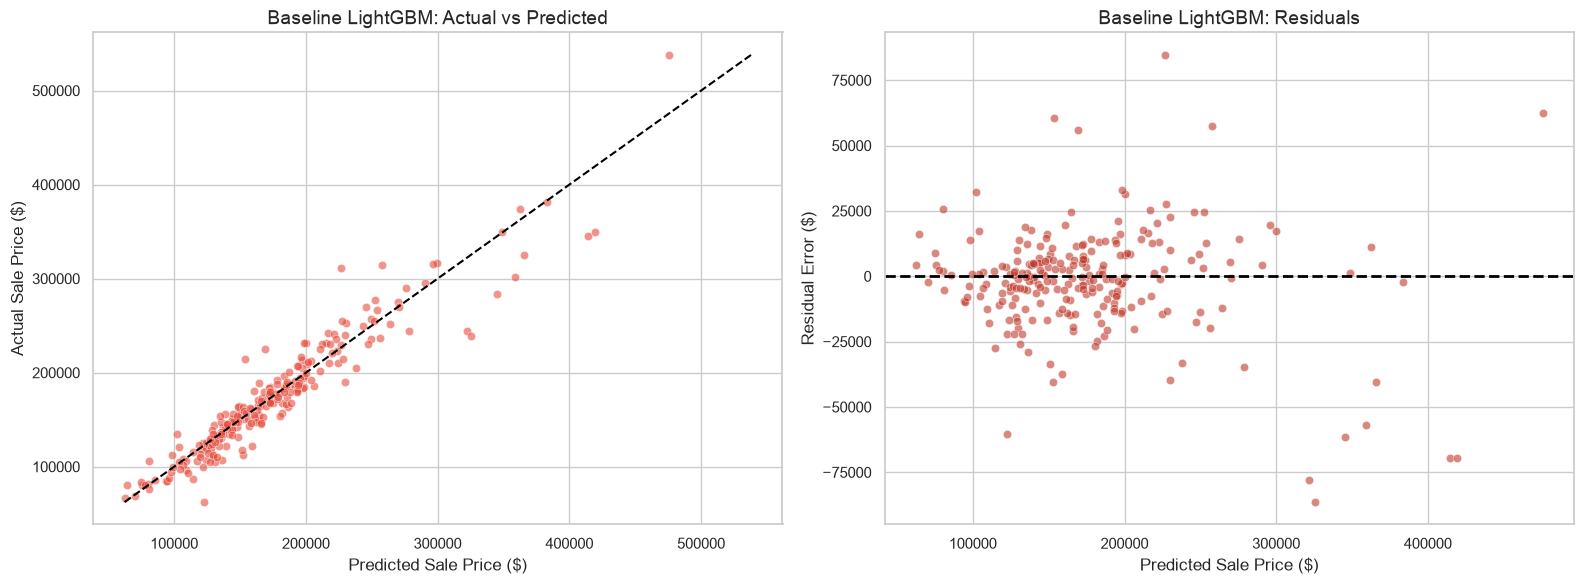

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs Predicted (Baseline)
sns.scatterplot(x=y_pred_150, y=y_test, alpha=0.6, color="#e74c3c", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
axes[0].set_title('Baseline LightGBM: Actual vs Predicted', fontsize=14)
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Actual Sale Price ($)')

# Plot 2: Residuals (Baseline)
residuals_base = y_test - y_pred_150
sns.scatterplot(x=y_pred_150, y=residuals_base, alpha=0.6, color="#c0392b", ax=axes[1])
axes[1].axhline(y=0, color="black", linestyle="--", lw=2)
axes[1].set_title('Baseline LightGBM: Residuals', fontsize=14)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


## 3. Hyperparameter Tuning (GridSearch)


> **Note:** We are tuning `learning_rate` and `num_leaves` to prevent the gradient boosting algorithm from memorizing the training data. We want it to learn slowly and generalize well.


In [4]:

X_train_tune = X_train_150
X_test_tune = X_test_150
feature_label = "150-Feature"

param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 300, 500],
    'num_leaves': [15, 31, 50],
    'max_depth': [-1, 5, 10]
}

print(f"Starting GridSearch on {feature_label} dataset... (This may take a couple of minutes)")
grid_search = GridSearchCV(LGBMRegressor(random_state=42, n_jobs=-1), param_grid, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1, verbose=1)
grid_search.fit(X_train_tune, y_train)

best_lgb = grid_search.best_estimator_
print(f"\nOptimal Hyperparameters: {grid_search.best_params_}")


Starting GridSearch on 150-Feature dataset... (This may take a couple of minutes)
Fitting 3 folds for each of 81 candidates, totalling 243 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007100 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2652
[LightGBM] [Info] Number of data points in the train set: 638, number of used features: 135
[LightGBM] [Info] Start training from score 176411.934169
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in featu

## 4. Evaluate Tuned Model (Diagnosing Overfitting)


In [5]:
y_train_pred = best_lgb.predict(X_train_tune)
y_test_pred = best_lgb.predict(X_test_tune)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

within_10 = (abs(y_test - y_test_pred) / y_test <= 0.10).mean() * 100

print("=== TUNED LIGHTGBM METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2:>15.4f} {test_r2:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse:>15,.2f} {test_rmse:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae:>15,.2f} {test_mae:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10:.1f}%")


=== TUNED LIGHTGBM METRICS ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9883          0.9040
RMSE ($)                         7,675.43       19,933.41
MAE ($)                          5,405.82       12,727.73
-------------------------------------------------------
Predictions within 10%: 76.2%


## 5. Diagnostic Plots (Did we fix the Heteroscedasticity?)


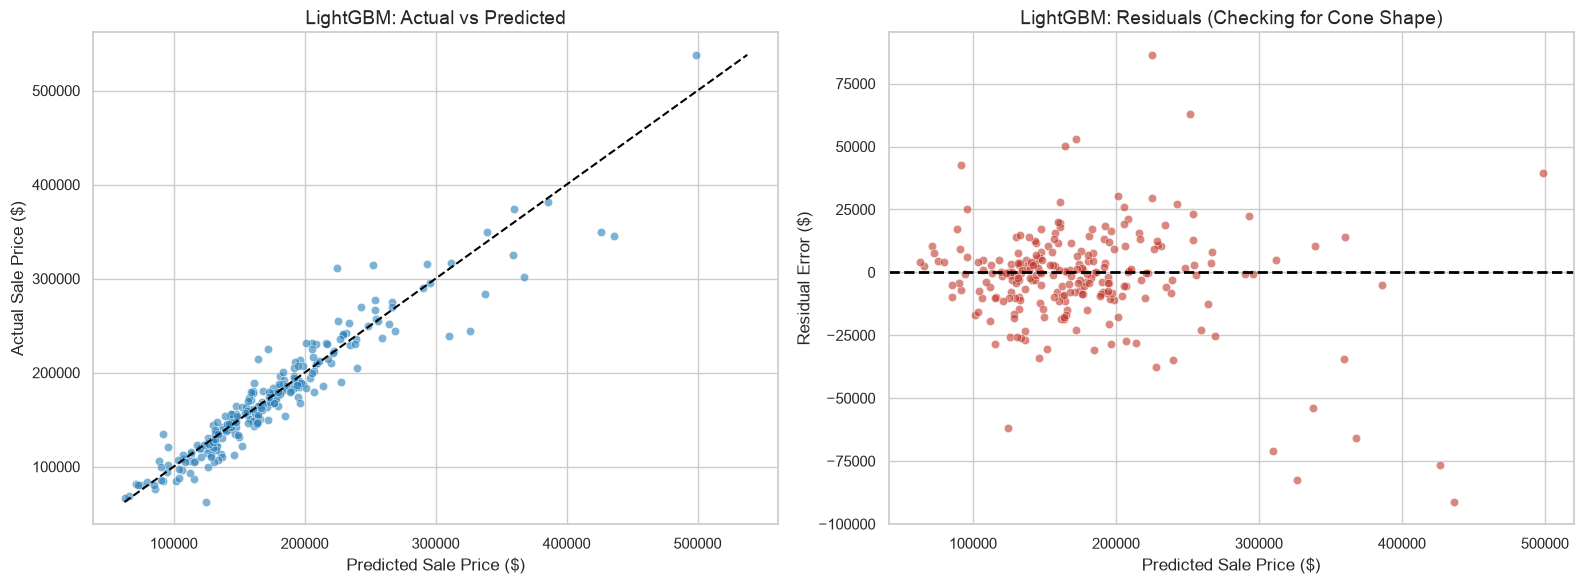

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs Predicted
sns.scatterplot(x=y_test_pred, y=y_test, alpha=0.6, color="#2980b9", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
axes[0].set_title('LightGBM: Actual vs Predicted', fontsize=14)
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Actual Sale Price ($)')

# Plot 2: Residuals
residuals = y_test - y_test_pred
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6, color="#c0392b", ax=axes[1])
axes[1].axhline(y=0, color="black", linestyle="--", lw=2)
axes[1].set_title('LightGBM: Residuals (Checking for Cone Shape)', fontsize=14)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


## 6. Feature Importance


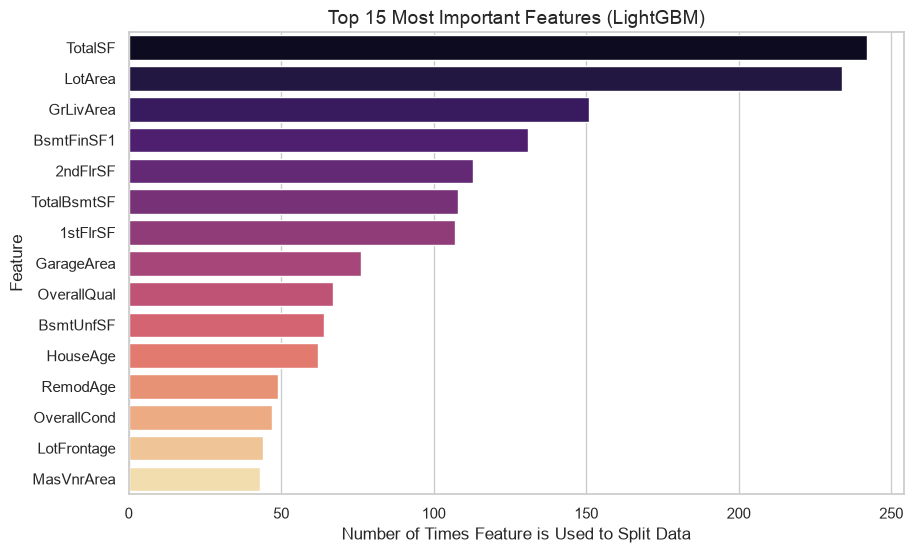

In [7]:
importances = best_lgb.feature_importances_
feature_names = X_train_tune.columns

# Create a DataFrame and sort
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')
plt.title('Top 15 Most Important Features (LightGBM)', fontsize=14)
plt.xlabel('Number of Times Feature is Used to Split Data')
plt.ylabel('Feature')
plt.show()


## 7. Save Final Model


In [8]:
os.makedirs('../../models', exist_ok=True)
os_path = '../../models/lightgbm_tuned.pkl'
joblib.dump(best_lgb, os_path)
print(f"LightGBM model successfully saved to: {os_path}")


LightGBM model successfully saved to: ../../models/lightgbm_tuned.pkl
